# EXP-04 — Phân tích Thực nghiệm CNN, Char-CNN & Hybrid RNN+Char-CNN (TV4)

- **Phạm vi:** Binary classification (`CLEAN=0`, `TOXIC=1`) theo SPEC v5.0.0.
- **Dữ liệu:** `data/processed/binary_n2_v1/` (`train=28,231`, `val=6,048`) và `binary_n4_training_v1/` (`train=33,906`, `val=6,048`).
- **Chống rò rỉ:** Tuyệt đối không đọc/chạm `test.parquet` trước N10.
- **Nguồn sự thật logic:** `src/models/cnn.py`, `src/models/cnn_pipeline.py`, và `src/evaluation/cnn_report.py`.


In [1]:
import json
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists() and (ROOT.parent / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

REPORT_DIR = (
    Path(OVERRIDE_REPORT_DIR)
    if 'OVERRIDE_REPORT_DIR' in globals()
    else ROOT / 'artifacts' / 'TV4-cnn-analysis'
)
report = json.loads(
    (REPORT_DIR / 'tv4_phase4_report.json').read_text(encoding='utf-8')
)
err_report = json.loads(
    (REPORT_DIR / 'tv4_error_analysis_val.json').read_text(encoding='utf-8')
)
print(
    f"Variants={report['n_variants_found']} | "
    f"Runs={report['n_runs_total']} | "
    f"Integrity={report['all_integrity_checks_passed']} | "
    f"Best={report['best_variant']}"
)


Variants=18 | Runs=54 | Integrity=True | Best=HYBRID-RNN-01


## 2. Bảng xếp hạng tổng hợp 18 biến thể × 3 seeds trên Validation

Xếp hạng chính thức dựa trên **Uncalibrated Validation Macro-F1** (`argmax` / ngưỡng `0.50`). Mọi mô hình đều đạt peak VRAM `< 250 MB` (`<< 7 GB`).


 rank          variant            arch  prep      macro_f1      f1_toxic  pr_auc  raw_ece  victsd_f1  vihsd_f1  params  vram_mb    best_seed
    1    HYBRID-RNN-01  bigru_char_cnn   raw 0.7733±0.0072 0.6149±0.0130  0.6673   0.0635     0.6542    0.7961 1964226    230.8 s42 (0.7806)
    2    HYBRID-RNN-WD  bigru_char_cnn   raw 0.7731±0.0052 0.6155±0.0103  0.6652   0.0653     0.6420    0.7982 1964226    208.2 s42 (0.7791)
    3        CNN-01-WD         textcnn basic 0.7705±0.0027 0.6058±0.0056  0.6751   0.0494     0.6211    0.7951 1307906    128.3 s42 (0.7734)
    4           CNN-01         textcnn basic 0.7702±0.0041 0.6065±0.0091  0.6734   0.0550     0.6285    0.7937 1307906    105.8 s42 (0.7740)
    5          CNN-04b         textcnn basic 0.7688±0.0045 0.6028±0.0112  0.6561   0.0769     0.6342    0.7907 1456130    129.8 s42 (0.7739)
    6          CNN-03a         textcnn basic 0.7679±0.0055 0.6018±0.0081  0.6661   0.0488     0.6242    0.7921 1357250    119.9 s43 (0.7714)
    7        

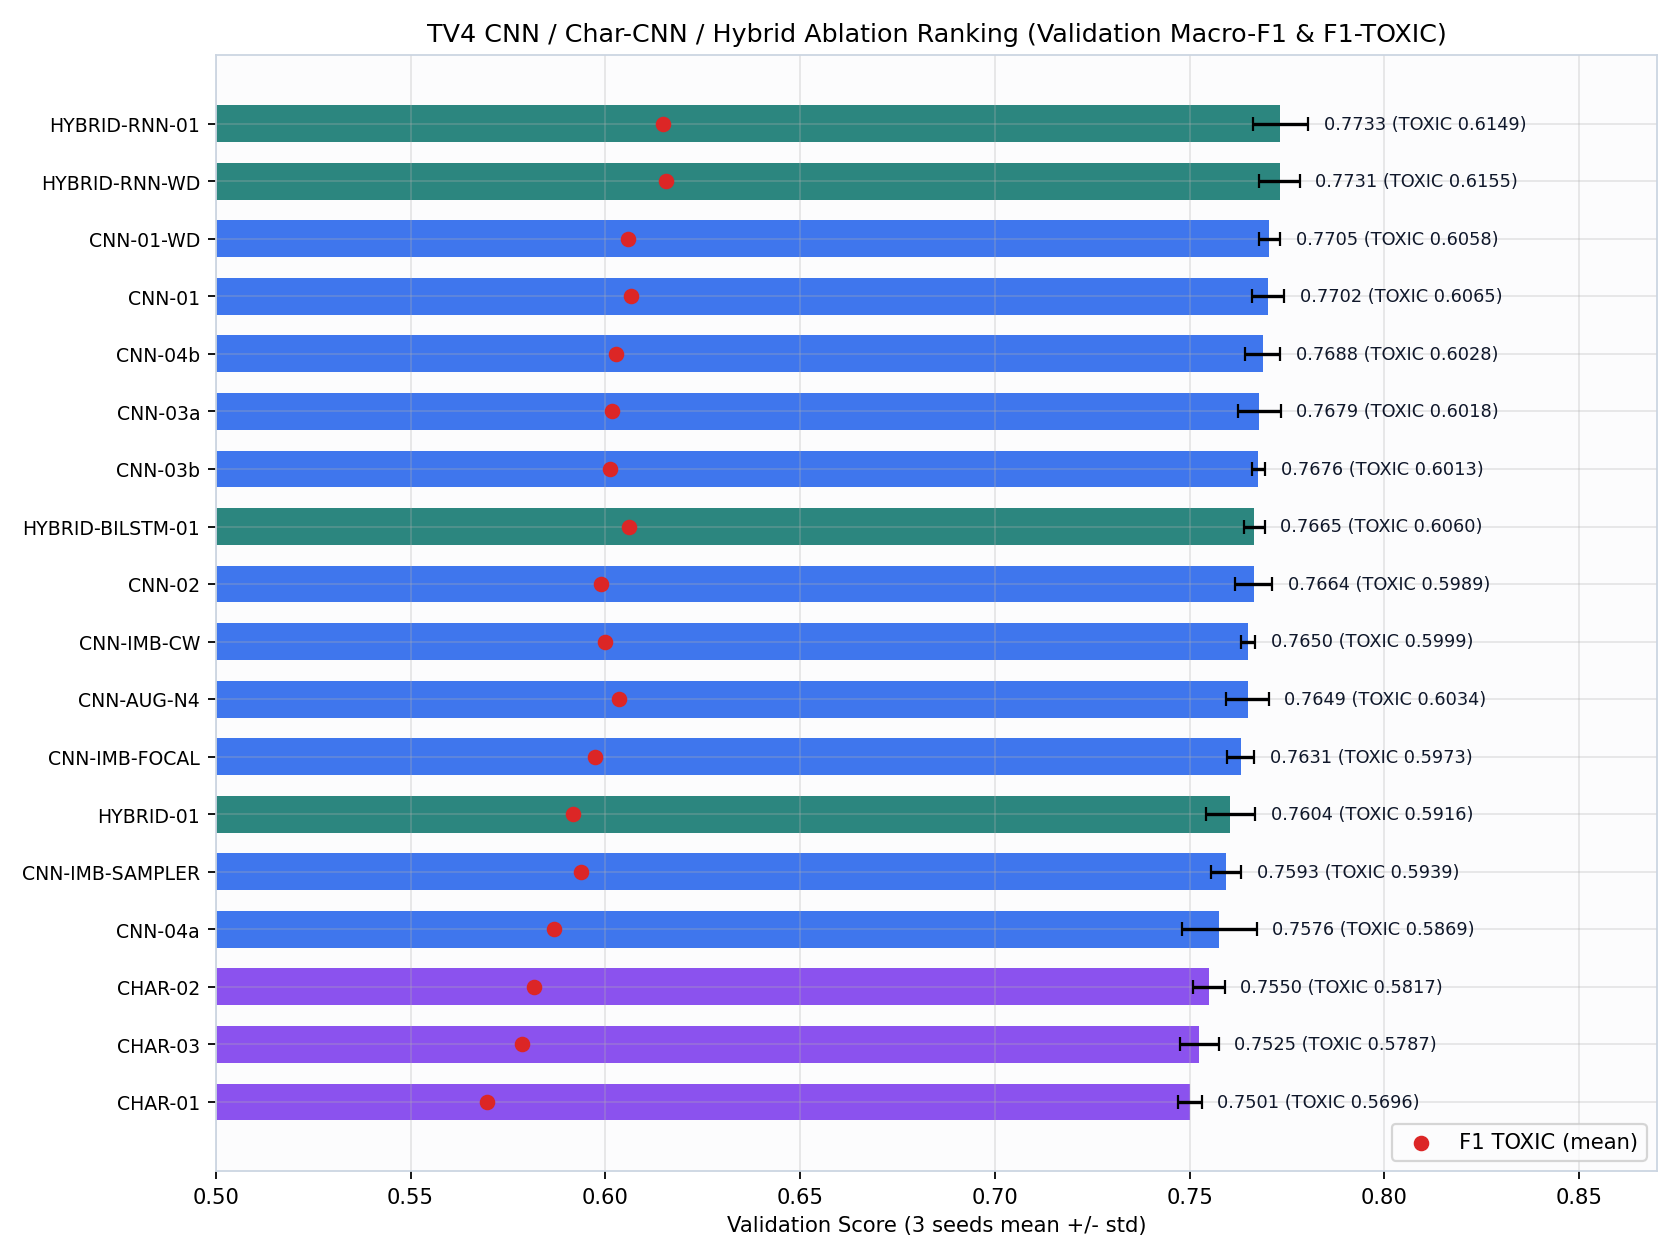

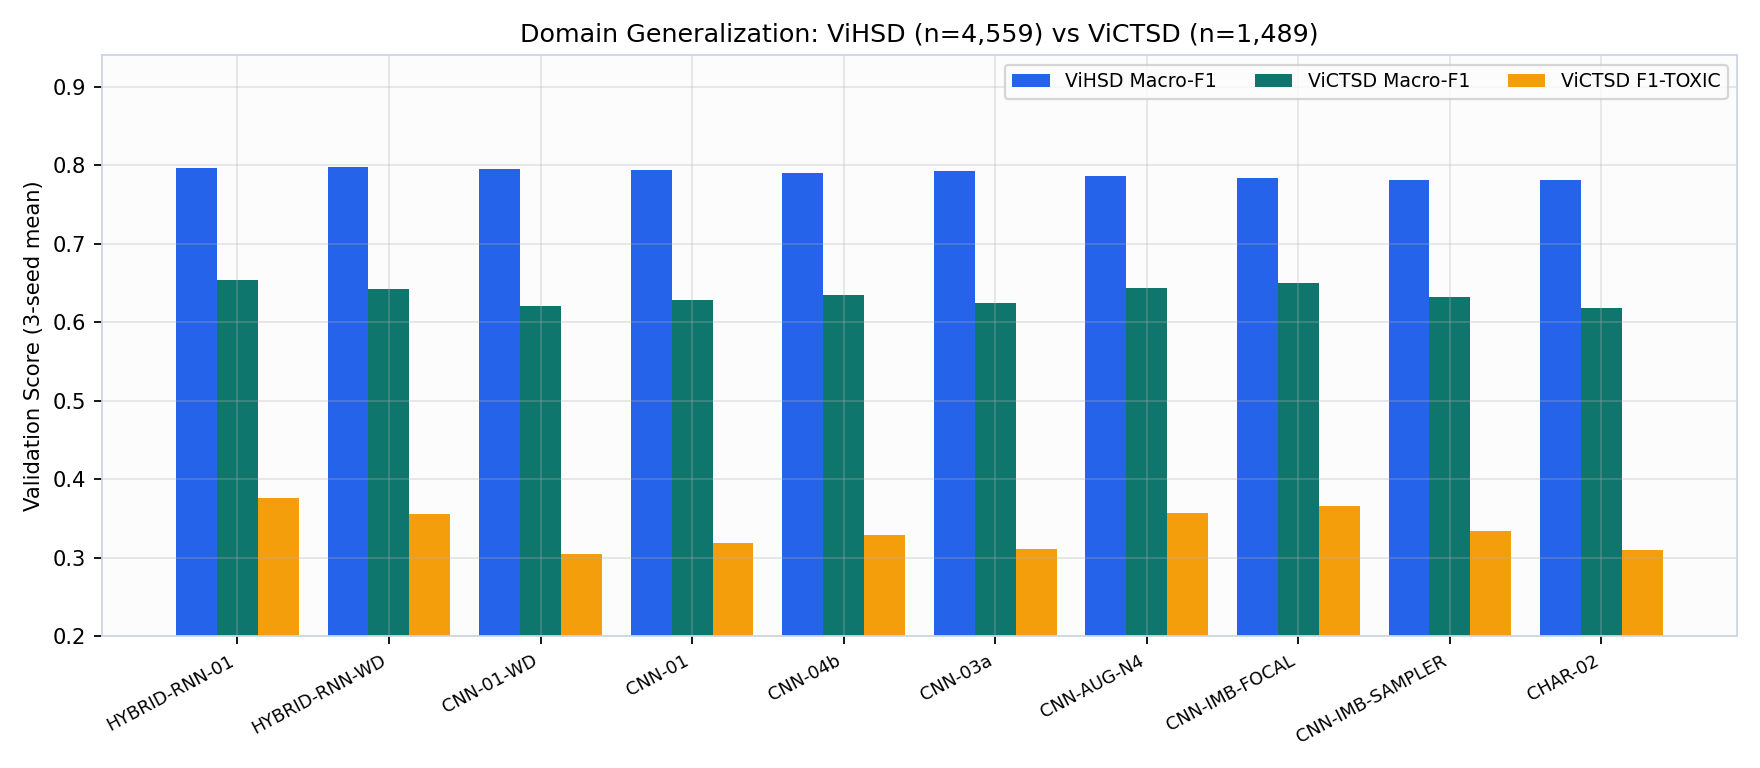

In [2]:
rows = []
for rank_idx, item in enumerate(report['ranking'], start=1):
    m_mean = item['macro_f1']['mean']
    m_std = item['macro_f1']['std']
    t_mean = item['f1_toxic']['mean']
    t_std = item['f1_toxic']['std']
    b_f1 = item['best_seed_macro_f1']
    rows.append({
        'rank': rank_idx,
        'variant': item['variant'],
        'arch': item['architecture'],
        'prep': item['preprocessing'],
        'macro_f1': f'{m_mean:.4f}±{m_std:.4f}',
        'f1_toxic': f'{t_mean:.4f}±{t_std:.4f}',
        'pr_auc': round(item['pr_auc']['mean'], 4),
        'raw_ece': round(item['raw_softmax_ece']['mean'], 4),
        'victsd_f1': round(item['by_source']['victsd']['macro_f1']['mean'], 4),
        'vihsd_f1': round(item['by_source']['vihsd']['macro_f1']['mean'], 4),
        'params': item['num_params'],
        'vram_mb': round(item['peak_vram_mb'], 1),
        'best_seed': f"s{item['best_seed']} ({b_f1:.4f})",
    })
ranking_df = pd.DataFrame(rows)
print(ranking_df.to_string(index=False))
_cell_charts = ['ablation_macro_f1.png', 'source_comparison.png']


## 3. Phân tích các vòng cải tiến theo Hướng 2 (Ablation Studies)

So sánh có đối chứng từng nhóm giả thuyết (chỉ thay đổi 1 yếu tố mỗi bước): Kernel sizes, Filters, Regularization (`dropout`/`weight_decay`), Imbalance D3, Augmentation N4, Char-CNN và Hybrid Word/BiLSTM/BiGRU + Char-CNN.


=== G1-Kernel ===
  CNN-01            | Macro-F1=0.7702 | F1-TOXIC=0.6065 | ViCTSD=0.6285 | ViHSD=0.7937
  CNN-02            | Macro-F1=0.7664 | F1-TOXIC=0.5989 | ViCTSD=0.6379 | ViHSD=0.7877
=== G2-Filters ===
  CNN-02            | Macro-F1=0.7664 | F1-TOXIC=0.5989 | ViCTSD=0.6379 | ViHSD=0.7877
  CNN-03a           | Macro-F1=0.7679 | F1-TOXIC=0.6018 | ViCTSD=0.6242 | ViHSD=0.7921
  CNN-03b           | Macro-F1=0.7676 | F1-TOXIC=0.6013 | ViCTSD=0.6277 | ViHSD=0.7901
=== G3-Reg ===
  CNN-02            | Macro-F1=0.7664 | F1-TOXIC=0.5989 | ViCTSD=0.6379 | ViHSD=0.7877
  CNN-04a           | Macro-F1=0.7576 | F1-TOXIC=0.5869 | ViCTSD=0.6276 | ViHSD=0.7805
  CNN-04b           | Macro-F1=0.7688 | F1-TOXIC=0.6028 | ViCTSD=0.6342 | ViHSD=0.7907
  CNN-01            | Macro-F1=0.7702 | F1-TOXIC=0.6065 | ViCTSD=0.6285 | ViHSD=0.7937
  CNN-01-WD         | Macro-F1=0.7705 | F1-TOXIC=0.6058 | ViCTSD=0.6211 | ViHSD=0.7951
=== G4-Imbalance-D3 ===
  CNN-02            | Macro-F1=0.7664 | F1-TOXIC=0.598

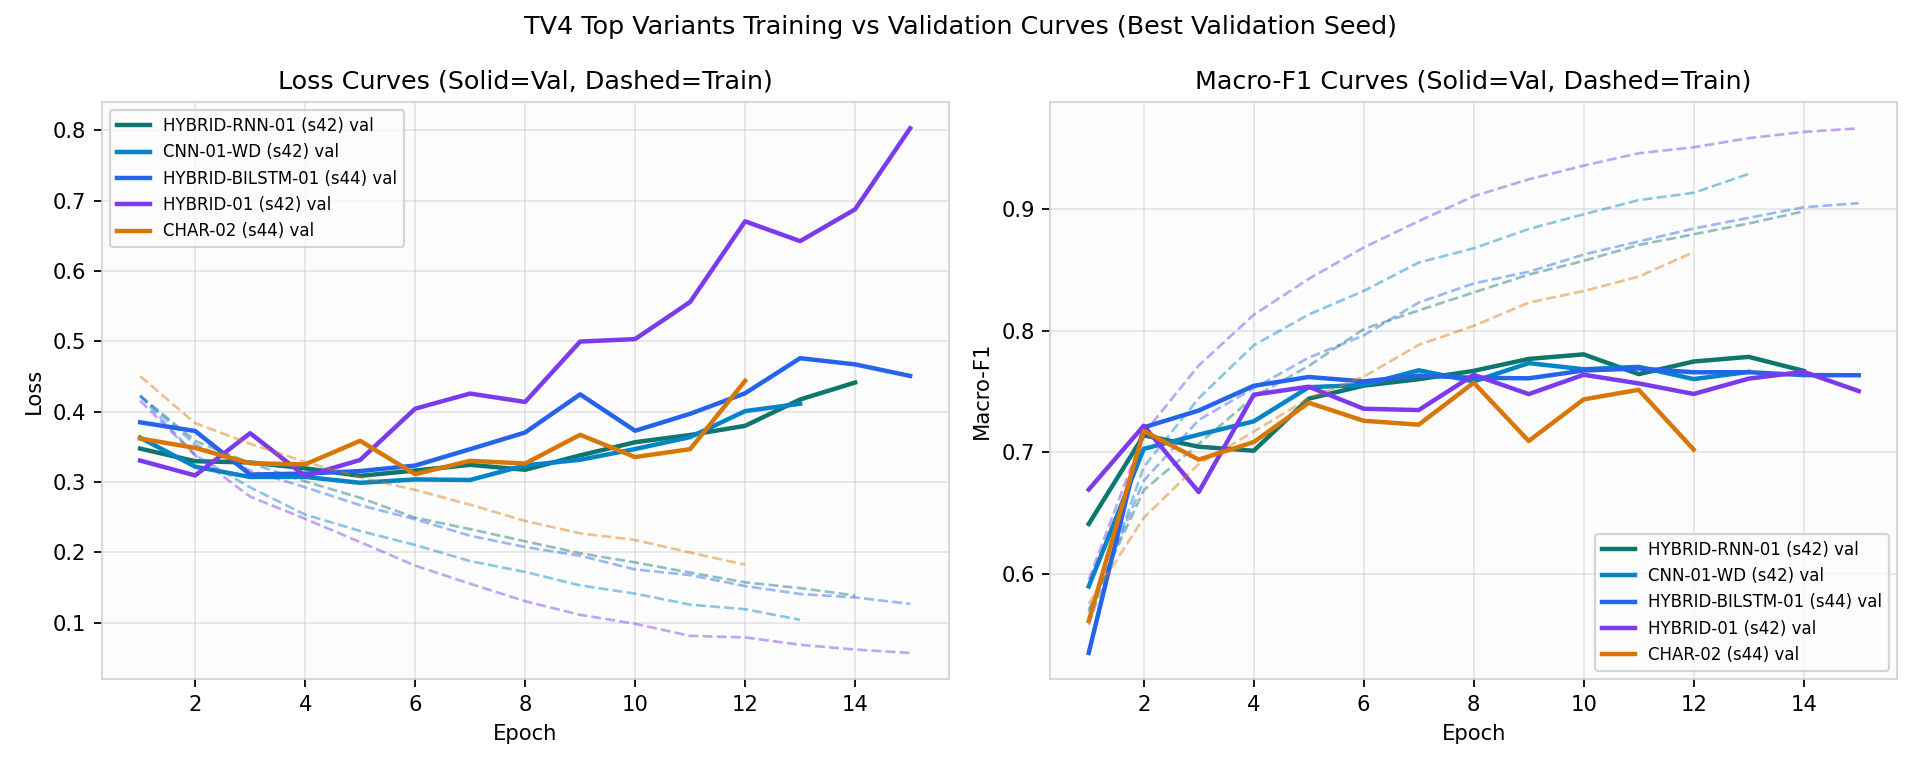

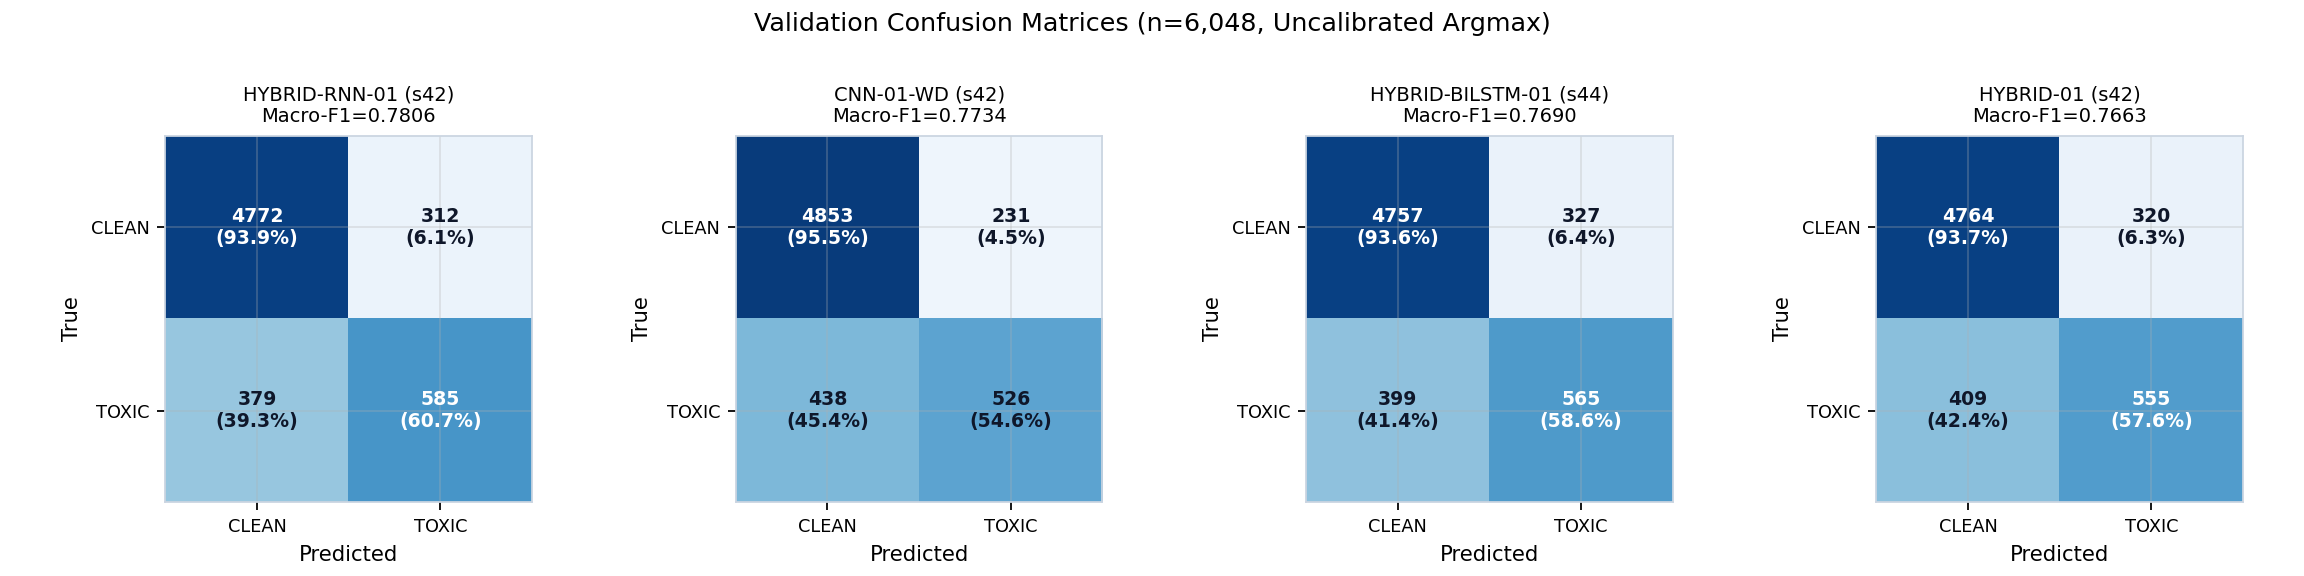

In [3]:
by_var = {x['variant']: x for x in report['ranking']}
groups = [
    ('G1-Kernel', ['CNN-01', 'CNN-02']),
    ('G2-Filters', ['CNN-02', 'CNN-03a', 'CNN-03b']),
    ('G3-Reg', ['CNN-02', 'CNN-04a', 'CNN-04b', 'CNN-01', 'CNN-01-WD']),
    (
        'G4-Imbalance-D3',
        ['CNN-02', 'CNN-IMB-CW', 'CNN-IMB-FOCAL', 'CNN-IMB-SAMPLER'],
    ),
    ('G5-Augment-N4', ['CNN-02', 'CNN-AUG-N4']),
    ('G6-CharCNN-N7', ['CHAR-01', 'CHAR-02', 'CHAR-03']),
    (
        'G7-Hybrid-N7',
        ['HYBRID-01', 'HYBRID-BILSTM-01', 'HYBRID-RNN-01', 'HYBRID-RNN-WD'],
    ),
]
for g_name, v_list in groups:
    present = [by_var[v] for v in v_list if v in by_var]
    if not present:
        continue
    print(f'=== {g_name} ===')
    for x in present:
        print(
            f"  {x['variant']:17s} | Macro-F1={x['macro_f1']['mean']:.4f} "
            f"| F1-TOXIC={x['f1_toxic']['mean']:.4f} "
            f"| ViCTSD={x['by_source']['victsd']['macro_f1']['mean']:.4f} "
            f"| ViHSD={x['by_source']['vihsd']['macro_f1']['mean']:.4f}"
        )
_cell_charts = ['learning_curves.png', 'confusion_matrices.png']


## 4. Chẩn đoán Calibration (Temperature vs Platt) & Threshold Sweep

Tất cả phép hiệu chuẩn xác suất và quét ngưỡng đều gắn cờ `in_sample_validation_only = True` và **không** dùng để đảo thứ tự chọn mô hình.


         variant  seed  uncal_macro_f1  raw_ece  temp_T  temp_ece  platt_ece  platt_opt_thr  in_sample_macro_f1  in_sample_f1_toxic
   HYBRID-RNN-01    42          0.7806   0.0636   1.774    0.0475     0.0078           0.35              0.7822              0.6303
   HYBRID-RNN-WD    42          0.7791   0.0644   1.784    0.0512     0.0109           0.34              0.7796              0.6268
       CNN-01-WD    42          0.7734   0.0546   1.626    0.0318     0.0064           0.33              0.7745              0.6169
          CNN-01    42          0.7740   0.0665   1.875    0.0444     0.0125           0.34              0.7749              0.6162
         CNN-04b    42          0.7739   0.0730   2.290    0.0477     0.0096           0.33              0.7756              0.6185
         CNN-03a    43          0.7714   0.0501   1.602    0.0338     0.0130           0.33              0.7724              0.6130
         CNN-03b    44          0.7687   0.0933   4.480    0.0323     0.0145

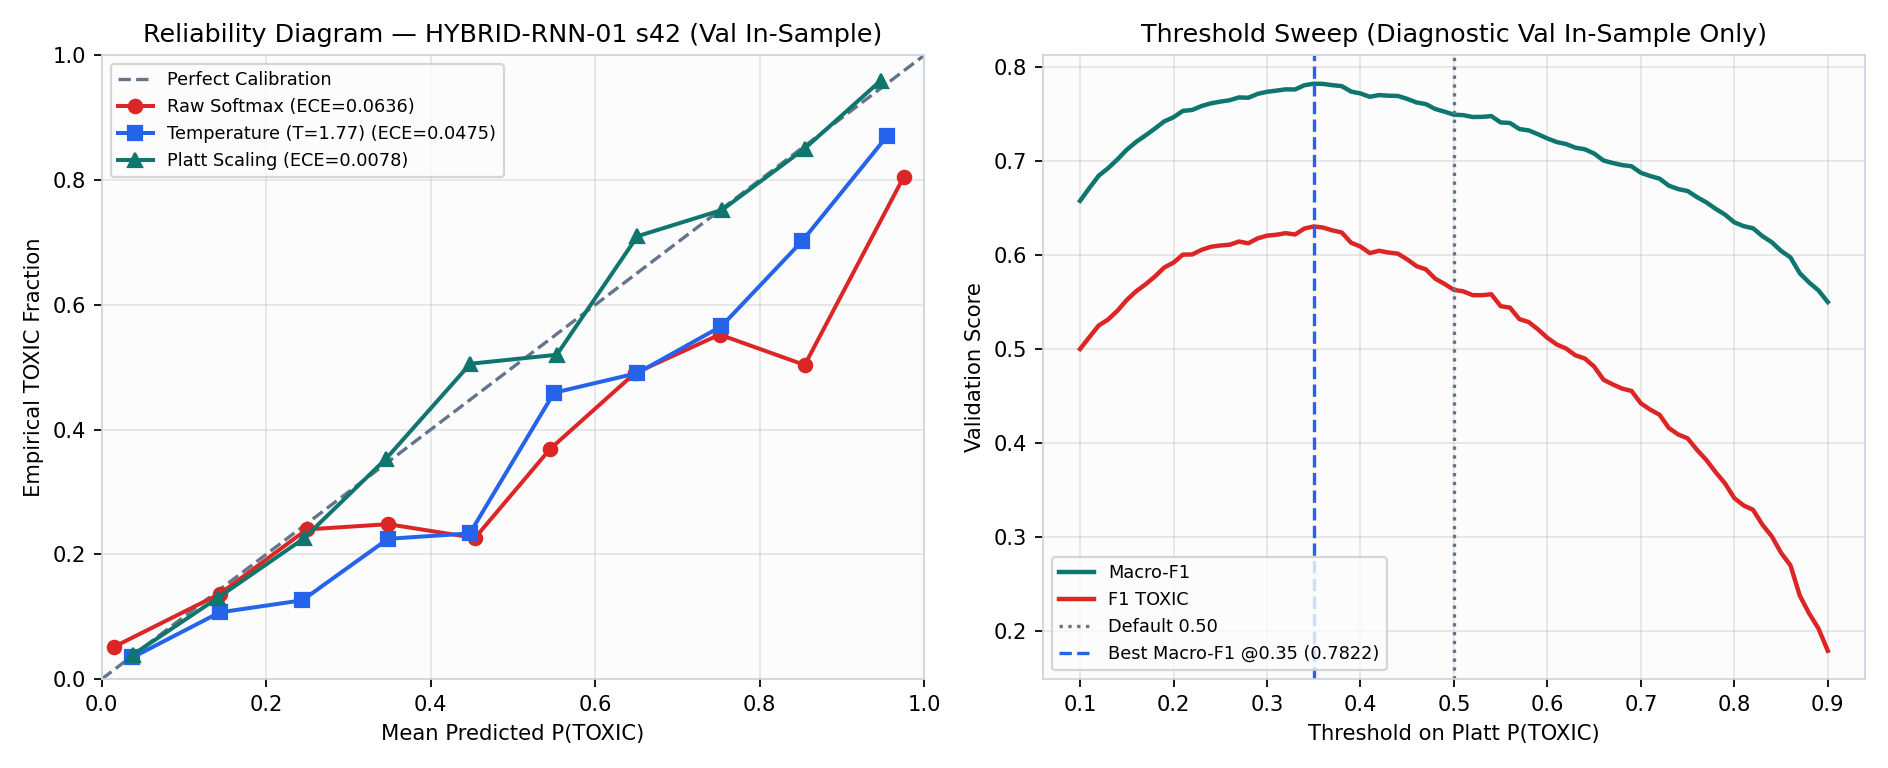

In [4]:
cal_rows = []
for c in report['calibrations']:
    sw = c['threshold_sweep_platt']
    cal_rows.append({
        'variant': c['variant'],
        'seed': c['seed'],
        'uncal_macro_f1': round(c['uncalibrated_val_macro_f1'], 4),
        'raw_ece': round(c['raw']['ece'], 4),
        'temp_T': round(c['temperature_scaling']['params']['temperature'], 3),
        'temp_ece': round(c['temperature_scaling']['metrics']['ece'], 4),
        'platt_ece': round(c['platt_scaling']['metrics']['ece'], 4),
        'platt_opt_thr': sw['best_macro_f1_threshold'],
        'in_sample_macro_f1': round(sw['best_macro_f1'], 4),
        'in_sample_f1_toxic': round(sw['f1_toxic_at_macro_opt'], 4),
    })
cal_df = pd.DataFrame(cal_rows)
print(cal_df.to_string(index=False))
_cell_charts = ['calibration_reliability.png']


## 5. Phân tích lỗi Validation ẩn danh (`>= 30` mẫu đã che PII)

Toàn bộ mẫu lỗi đại diện đều được che `<USER>`, `<URL>`, `<EMAIL>`, `<NUM>`, `<NAME>` và giới hạn tối đa 84 ký tự theo quy tắc bảo vệ quyền riêng tư.


In [5]:
prim = err_report['primary']
agg = prim['aggregate_error_summary']
n_err = agg['n_errors_total']
n_tot = agg['n_val_total']
print(
    f"Primary={prim['variant']} (s{prim['seed']}) | "
    f"Errors={n_err}/{n_tot} ({agg['error_rate']:.2%}) | "
    f"Pairs={agg['confusion_pair_counts']}"
)
tag_df = pd.DataFrame.from_dict(prim['error_rate_by_tag'], orient='index')
print('\n--- Error Rate by Linguistic Tag ---')
print(tag_df.to_string())
len_buckets = prim['error_rate_by_length_bucket']
len_df = pd.DataFrame.from_dict(len_buckets, orient='index')
print('\n--- Error Rate by Length Bucket ---')
print(len_df.to_string())
ex_rows = [
    {
        'id12': ex['sample_id'][:12],
        'src': ex['source'],
        'type': ex['error_type'],
        'p_tox': round(ex['prob_toxic'], 4),
        'words': ex['word_count'],
        'tags': ','.join(ex['tags']),
        'redacted_snippet': ex['redacted_snippet'],
    }
    for ex in prim['representative_examples']
]
print(f'\n--- {len(ex_rows)} Privacy-Redacted Validation Error Examples ---')
print(pd.DataFrame(ex_rows).to_string(index=False))


Primary=HYBRID-RNN-01 (s42) | Errors=691/6048 (11.43%) | Pairs={'TOXIC -> CLEAN': 379, 'CLEAN -> TOXIC': 312}

--- Error Rate by Linguistic Tag ---
                              n_samples  n_errors  error_rate
contains_emoji_or_punct             762        71      0.0932
contains_negation                  1640       258      0.1573
contains_teencode                  1156       179      0.1548
contains_url_or_mention              23         4      0.1739
context_or_lexical_nuance          1836       180      0.0980
long_text_ge_35_words               638       114      0.1787
obfuscated_or_repeated_chars       1031       145      0.1406
short_text_le_5_words              1438       108      0.0751

--- Error Rate by Length Bucket ---
                n_samples  n_errors  error_rate
16_to_30_words       1127       187      0.1659
6_to_15_words        2700       258      0.0956
gt_30_words           783       138      0.1762
le_5_words           1438       108      0.0751

--- 40 Privacy-R

## 6. Kết luận chọn ứng viên cho Phần 5 (Ensemble) & Phần 6 (Locked Test N10)

1. **Ứng viên #1 (Hybrid RNN+Char-CNN):** `HYBRID-RNN-01` (Macro-F1 `0.7733 ± 0.0072`, best seed 42 `0.7806`, Platt ECE `0.0078`) và `HYBRID-RNN-WD` (`0.7731 ± 0.0052`, F1-TOXIC `0.6155`).
2. **Ứng viên #2 (Pure Word TextCNN nhanh/nhẹ):** `CNN-01-WD` (`0.7705 ± 0.0027`, Platt ECE `0.0064`, inference `0.050 ms/sample`) và `CNN-01` (`0.7702 ± 0.0041`).
3. **Ứng viên #3 (Pure Char-CNN hình thái ký tự):** `CHAR-02` (`0.7550 ± 0.0040`, `345,666` params, `3.98 MB`) bổ sung đa dạng kiến trúc.


## 7. Phần 5 (EXP-06) — Error Diversity & Conditional Ensemble (TV4 + TV2)

Kiểm định độ đa dạng lỗi (`disagreement_rate`, `double_fault_rate`, `oracle_macro_f1`) và đánh giá Soft/Weighted Probability Voting cùng 5-Fold Out-of-Fold Platt Calibrated Voting đối chiếu ngưỡng ADR `+1.0%`.


ADR Gate Summary: {"adr_min_gain_required": 0.01, "best_tv4_single_macro_f1": 0.7733, "best_n6_cal_050_macro_f1": 0.7836, "best_n6_uncal_macro_f1": 0.7892, "intra_tv4_winner": "ENS-TV4-DIVERSE-6", "intra_tv4_winner_macro_f1": 0.7859, "intra_tv4_gain": 0.0126, "intra_tv4_passes_adr": true, "cross_team_winner": "ENS-CROSS-OOF-PLATT", "cross_team_winner_macro_f1": 0.7989, "cross_team_gain_vs_n6_cal_050": 0.0153, "cross_team_gain_vs_n6_uncal": 0.0098, "stacking_train_oof_decision": "SKIP_TRAIN_OOF_FOR_PRODUCTION: Generating 5-fold Train-OOF across 6 neural architectures x 3 seeds requires 90 GPU training runs (~2.5h GPU) while 5-fold Val-OOF Logistic Stacking offers no gain over calibrated Weighted Probability Voting. Valid Probability Voting is selected per AGENTS.md §6."}
                 ensemble      scope                       protocol      macro_f1      f1_toxic  victsd_f1  vihsd_f1  gain_vs_tv4  gain_vs_n6_cal  gain_vs_n6_uncal
          ENS-TV4-INTRA-3  intra_tv4               fixe

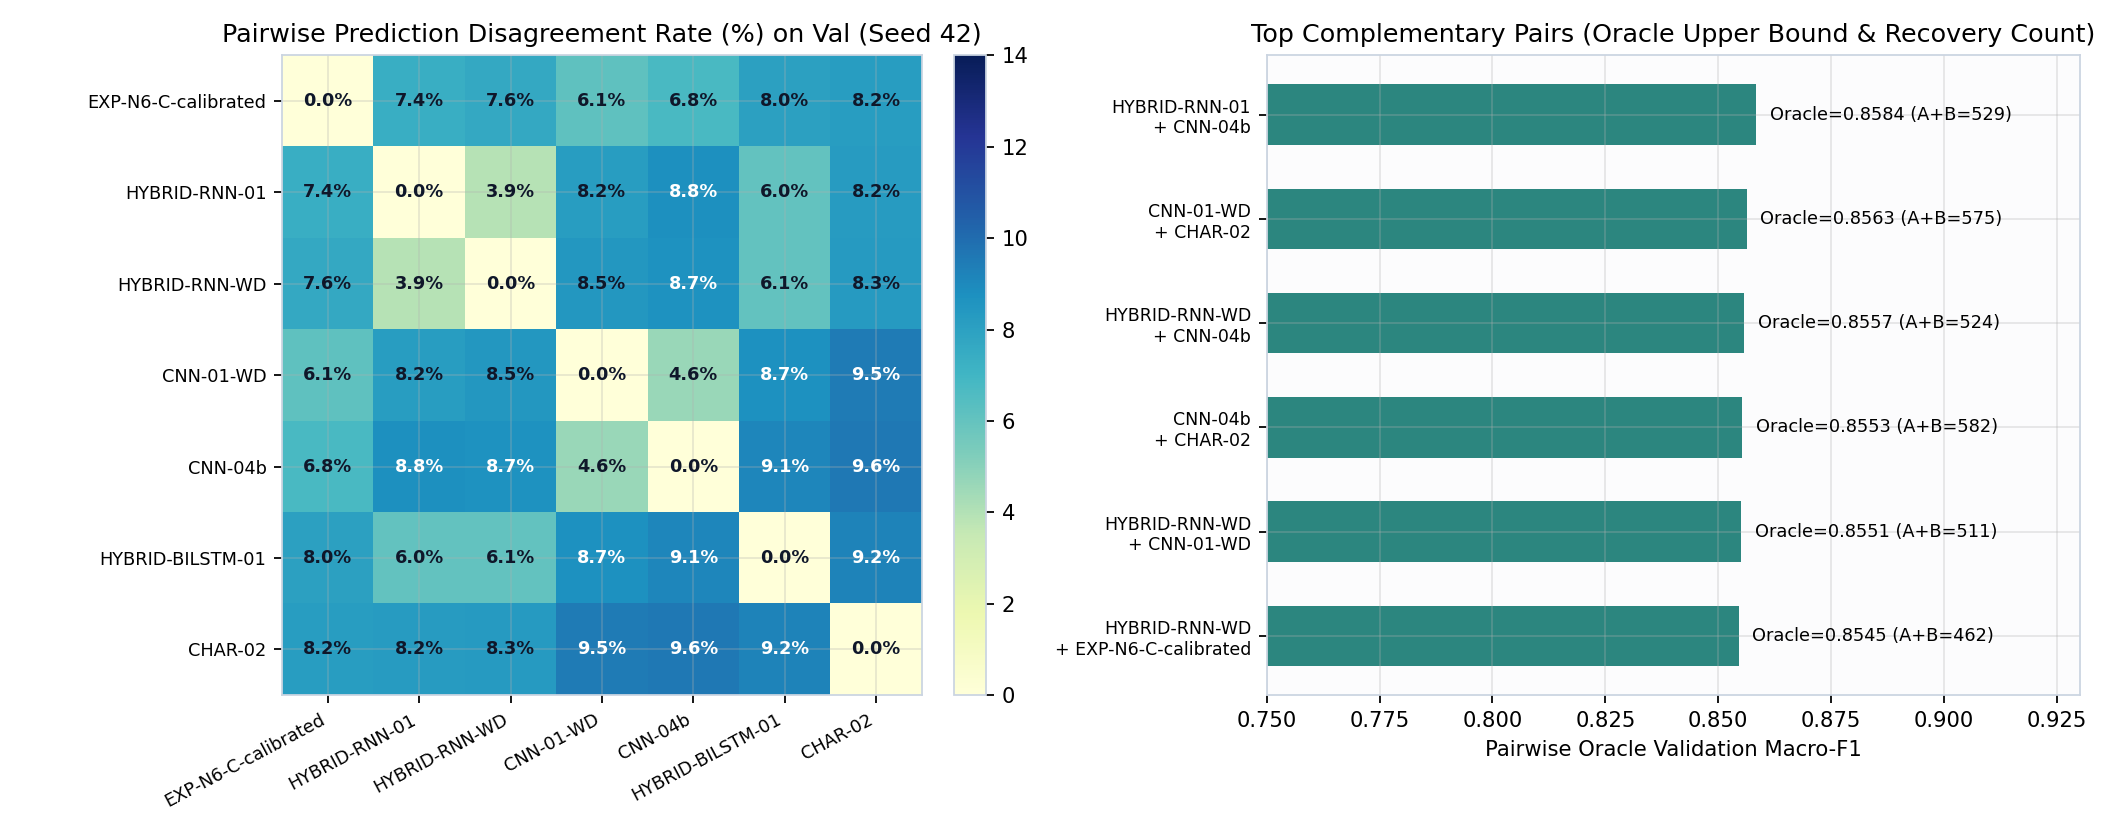

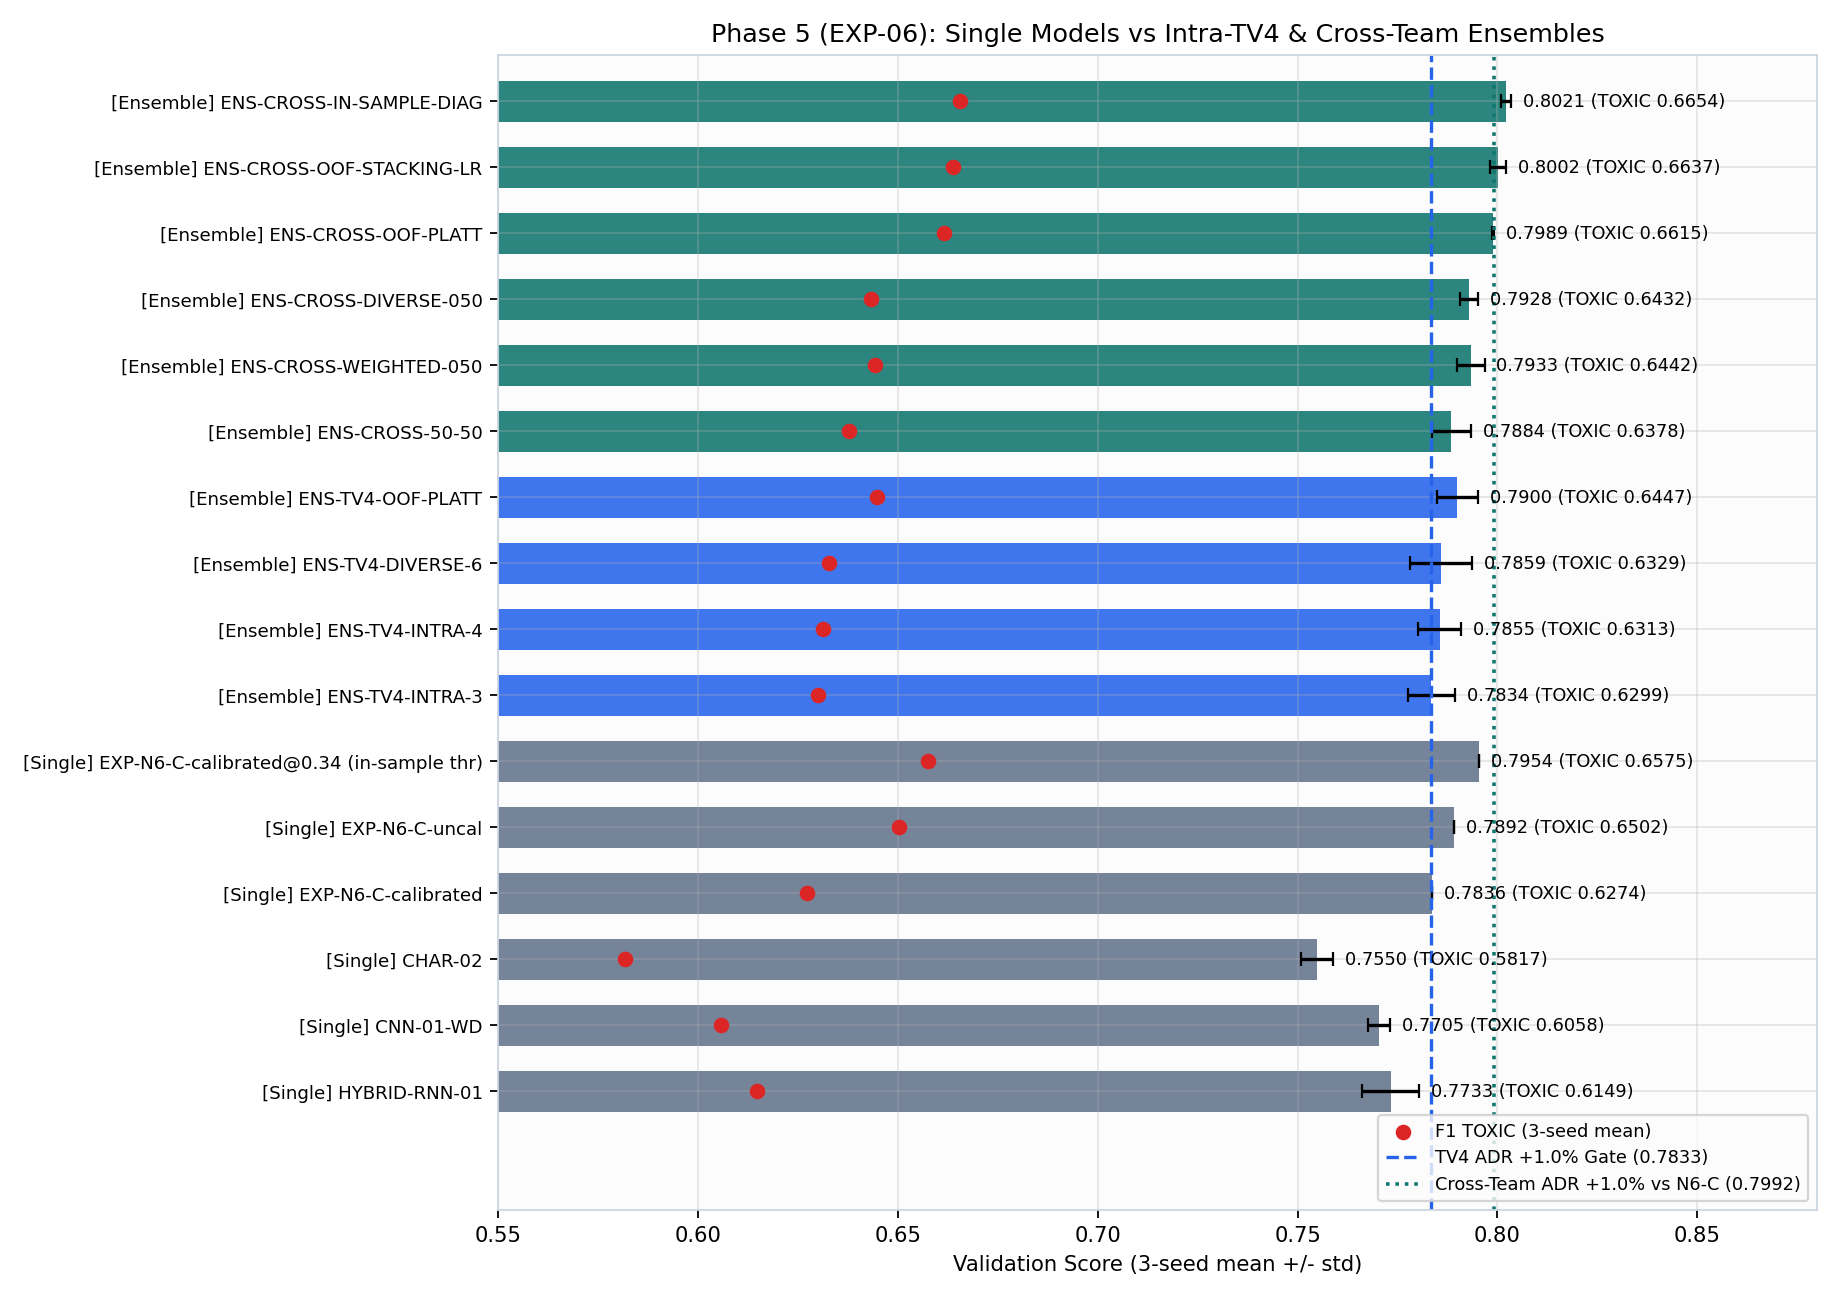

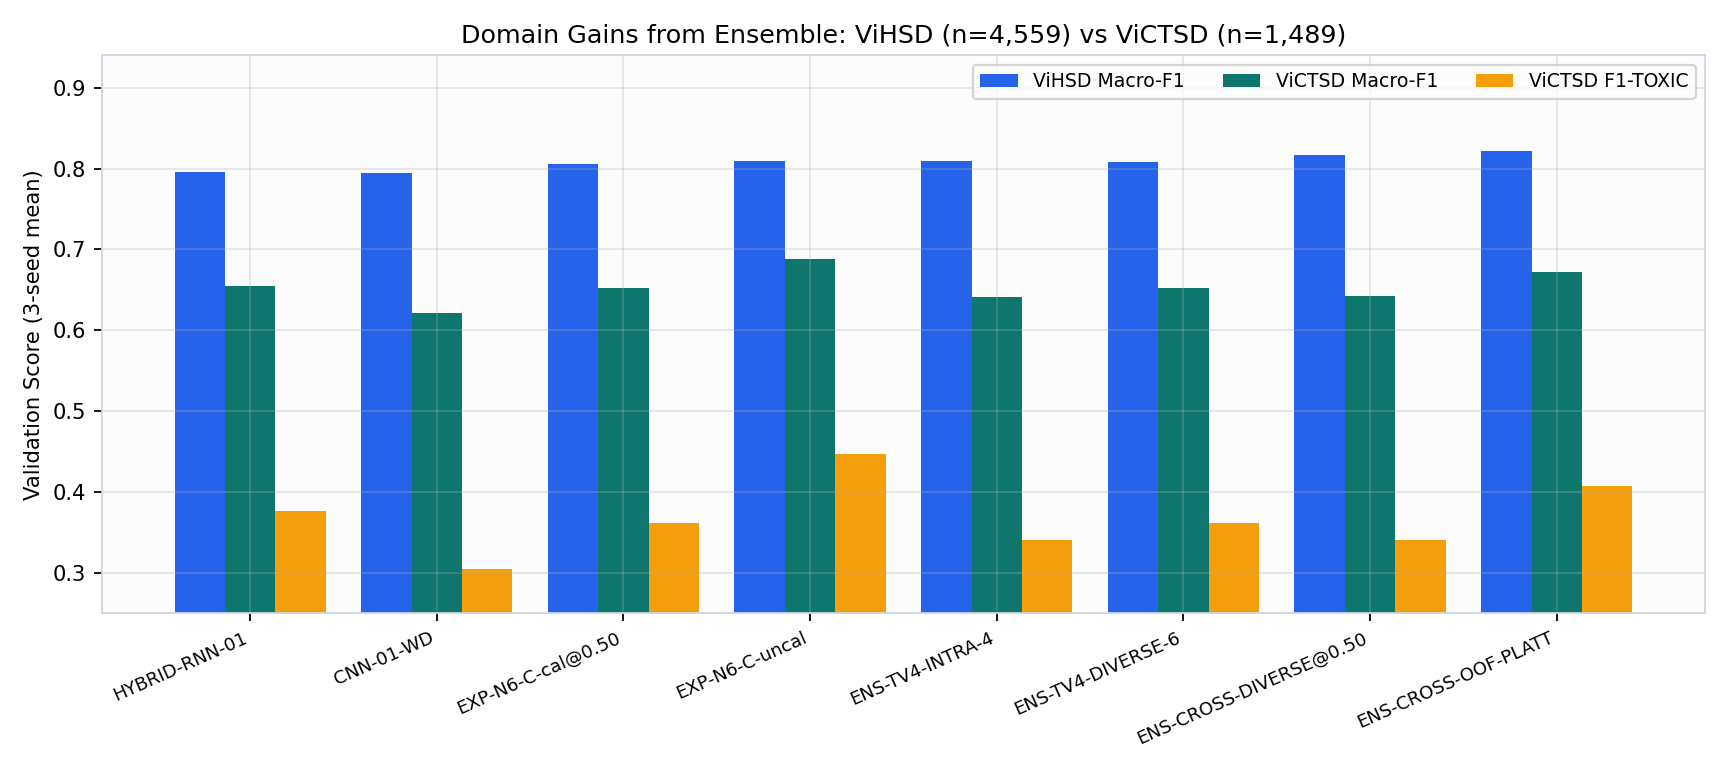

In [6]:
ens_path = REPORT_DIR.parent / 'TV4-ensemble-analysis' / (
    'tv4_phase5_ensemble_report.json'
)
if ens_path.exists():
    ens_rep = json.loads(ens_path.read_text(encoding='utf-8'))
    adr = ens_rep['adr_decision']
    print('ADR Gate Summary:', json.dumps(adr, ensure_ascii=False))
    e_rows = [
        {
            'ensemble': e['name'],
            'scope': e['scope'],
            'protocol': e['protocol'],
            'macro_f1': (
                f"{e['macro_f1']['mean']:.4f}±{e['macro_f1']['std']:.4f}"
            ),
            'f1_toxic': (
                f"{e['f1_toxic']['mean']:.4f}±{e['f1_toxic']['std']:.4f}"
            ),
            'victsd_f1': round(
                e['by_source']['victsd']['macro_f1']['mean'], 4
            ),
            'vihsd_f1': round(
                e['by_source']['vihsd']['macro_f1']['mean'], 4
            ),
            'gain_vs_tv4': e['gain_vs_best_tv4_single'],
            'gain_vs_n6_cal': e['gain_vs_n6_cal_050'],
            'gain_vs_n6_uncal': e['gain_vs_n6_uncal_margin'],
        }
        for e in ens_rep['ensembles']
    ]
    print(pd.DataFrame(e_rows).to_string(index=False))
    _cell_charts = [
        '../TV4-ensemble-analysis/error_diversity_heatmap.png',
        '../TV4-ensemble-analysis/ensemble_comparison.png',
        '../TV4-ensemble-analysis/ensemble_source_gains.png',
    ]
else:
    print('Phase 5 ensemble report not generated in this directory.')


## 8. One-Shot Locked Test Evaluation (`N10` / `EXP-08`)

Đánh giá một lần duy nhất (`one-shot`) danh sách mô hình đơn và ensemble đã đóng băng từ validation trên `data/processed/binary_n2_v1/test.parquet` (`n = 6,048`, SHA-256 `d200be4a7ff2f2e725ba8e6c2c0ab835afd73612b9a5b2f14b528cb5c577be4e`). Không có bất kỳ bước chọn mô hình, tinh chỉnh trọng số hay tối ưu ngưỡng nào được thực hiện trên tập test.

In [7]:
locked_report_path = (
    REPORT_DIR.parent
    / 'TV4-locked-test'
    / 'tv4_n10_locked_test_report.json'
)
if locked_report_path.exists():
    locked_rep = json.loads(locked_report_path.read_text(encoding='utf-8'))
    locked_rows = []
    for m in locked_rep['single_models']:
        at050 = m['at_050']
        platt = m['at_frozen_platt']
        gap = m['generalization_gap_macro_f1']
        locked_rows.append({
            'group': 'Single (TV4)',
            'candidate': m['variant'],
            'val_macro_f1': round(m['val_macro_f1_mean'], 4),
            'test_macro_f1_050': round(at050['test_macro_f1']['mean'], 4),
            'test_f1_toxic_050': round(at050['test_f1_toxic']['mean'], 4),
            'test_macro_f1_platt': round(platt['test_macro_f1']['mean'], 4),
            'test_ece_platt': round(platt['test_ece']['mean'], 4),
            'delta_test_minus_val': round(gap, 4),
        })
    tv2_ref = locked_rep['n6_reference']
    tv2_050 = tv2_ref['at_050']
    tv2_034 = tv2_ref['at_frozen_034']
    locked_rows.append({
        'group': 'Single (TV2 Ref)',
        'candidate': 'EXP-N6-C-calibrated (@0.50 / @0.34)',
        'val_macro_f1': 0.7836,
        'test_macro_f1_050': round(tv2_050['macro_f1'], 4),
        'test_f1_toxic_050': round(tv2_050['f1_toxic'], 4),
        'test_macro_f1_platt': round(tv2_034['macro_f1'], 4),
        'test_ece_platt': round(tv2_050['ece'], 4),
        'delta_test_minus_val': round(tv2_050['macro_f1'] - 0.7836, 4),
    })
    for e in locked_rep['ensembles']:
        locked_rows.append({
            'group': f"Ensemble ({e['scope']})",
            'candidate': e['name'],
            'val_macro_f1': round(e['val_macro_f1_mean'], 4),
            'test_macro_f1_050': round(e['test_macro_f1']['mean'], 4),
            'test_f1_toxic_050': round(e['test_f1_toxic']['mean'], 4),
            'test_macro_f1_platt': round(e['test_macro_f1']['mean'], 4),
            'test_ece_platt': round(e['test_ece']['mean'], 4),
            'delta_test_minus_val': round(e['generalization_gap_macro_f1'], 4),
        })
    print(pd.DataFrame(locked_rows).to_string(index=False))
    _locked_charts = [
        '../TV4-locked-test/locked_test_val_vs_test.png',
        '../TV4-locked-test/locked_test_confusion_matrices.png',
        '../TV4-locked-test/locked_test_source_breakdown.png',
    ]
else:
    print('Phase 6 locked test report not generated in this directory.')


                group                           candidate  val_macro_f1  test_macro_f1_050  test_f1_toxic_050  test_macro_f1_platt  test_ece_platt  delta_test_minus_val
         Single (TV4)                       HYBRID-RNN-01        0.7733             0.7855             0.6352               0.7854          0.0112                0.0122
         Single (TV4)                       HYBRID-RNN-WD        0.7731             0.7808             0.6278               0.7805          0.0100                0.0077
         Single (TV4)                           CNN-01-WD        0.7705             0.7839             0.6290               0.7851          0.0139                0.0135
         Single (TV4)                              CNN-01        0.7702             0.7867             0.6350               0.7865          0.0146                0.0166
         Single (TV4)                             CNN-04b        0.7688             0.7754             0.6140               0.7757          0.0131         